<div style='font-family:Segoe UI,Roboto,Helvetica,Arial,sans-serif;border-radius:12px;overflow:hidden;border:1px solid #D5E3DA'><div style='background:linear-gradient(135deg,#0B3D2E 0%,#00703C 70%,#1F8A4C 100%);color:#FFFFFF;padding:22px 26px 20px'><div style='display:flex;justify-content:space-between;flex-wrap:wrap;gap:8px;font-size:12px;letter-spacing:.12em;text-transform:uppercase'><span><b>Banque africaine de développement</b> · Data Innovation for Africa (DI4A)</span><span style='opacity:.85'>Notebook 3 / 3</span></div><div style='font-size:13px;margin-top:14px;opacity:.9'>Atelier BAD – Centre Big Data du FMI · ATI</div><div style='font-size:24px;font-weight:700;line-height:1.25;margin-top:2px'>Big Data pour les statistiques macroéconomiques</div><div style='font-size:14px;opacity:.9;margin-top:2px'>26 – 30 octobre 2026 · Maurice</div><div style='margin-top:16px;padding:12px 14px;background:rgba(0,0,0,0.18);border-left:4px solid #C8A13A;border-radius:6px'><div style='font-size:12px;letter-spacing:.08em;text-transform:uppercase;color:#C8A13A;font-weight:700'>Session · jeudi 29 octobre · 11 h 30 – 12 h 30</div><div style='font-size:17px;font-weight:700;margin-top:3px'>Données alternatives pour améliorer la mesure de l'IPC</div><div style='font-size:13px;opacity:.9'>BAD (DI4A) et INS de Côte d'Ivoire — prix en ligne, prix administrés, correspondance COICOP, étalonnage des indices</div></div><div style='display:flex;gap:8px;margin-top:16px;flex-wrap:wrap'><div style='flex:1;min-width:150px;background:rgba(255,255,255,0.10);color:#FFFFFF;border:2px solid rgba(255,255,255,0.25);border-radius:8px;padding:9px 12px'><div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;opacity:.8'>Notebook 1</div><div style='font-weight:700;font-size:15px'>Collecte Jumia</div><div style='font-size:12px;opacity:.85'>Relever les prix en ligne</div></div><div style='align-self:center;color:#C8A13A;font-size:20px;font-weight:700'>&#8594;</div><div style='flex:1;min-width:150px;background:rgba(255,255,255,0.10);color:#FFFFFF;border:2px solid rgba(255,255,255,0.25);border-radius:8px;padding:9px 12px'><div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;opacity:.8'>Notebook 2</div><div style='font-weight:700;font-size:15px'>Autres sources</div><div style='font-size:12px;opacity:.85'>Prix administrés et institutionnels</div></div><div style='align-self:center;color:#C8A13A;font-size:20px;font-weight:700'>&#8594;</div><div style='flex:1;min-width:150px;background:#FFFFFF;color:#0B3D2E;border:2px solid #C8A13A;border-radius:8px;padding:9px 12px'><div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;opacity:.8'>Notebook 3</div><div style='font-weight:700;font-size:15px'>Analyse</div><div style='font-size:12px;opacity:.85'>Classer, calculer l'indice, rendre compte</div></div></div></div><div style='background:#FFFFFF;padding:12px 26px 6px'><span style='display:inline-block;background:#F3F6F4;border:1px solid #D5E3DA;border-radius:999px;padding:4px 12px;margin:0 8px 6px 0;font-size:13px;color:#0B3D2E'><b>Exécution</b> · Colab ou poste local</span><span style='display:inline-block;background:#F3F6F4;border:1px solid #D5E3DA;border-radius:999px;padding:4px 12px;margin:0 8px 6px 0;font-size:13px;color:#0B3D2E'><b>Entrée</b> · les archives des notebooks 1 et 2</span><span style='display:inline-block;background:#F3F6F4;border:1px solid #D5E3DA;border-radius:999px;padding:4px 12px;margin:0 8px 6px 0;font-size:13px;color:#0B3D2E'><b>Produit</b> · rapport.html autonome</span></div></div>

# Indice des prix en ligne — analyse

**Pour qui.** Vous n'avez rien à installer et aucune ligne de code à écrire.
Chaque cellule se lance avec le bouton ▶ à sa gauche, de haut en bas.

**Ce que fait ce notebook.** Il part des relevés produits par les notebooks 1
et 2, les **agrège**, les contrôle, classe les produits dans la nomenclature internationale COICOP,
**compare les méthodes de classification entre elles**, calcule un indice des
prix et produit un rapport à télécharger.

**Ce qu'il ne fait pas.** Il ne va jamais sur un site marchand. La collecte se
fait ailleurs, sur le poste de l'institut. Ce notebook ne travaille que sur des
fichiers.

---

**Tout se règle dans la cellule suivante.** Les valeurs par défaut mènent au jeu
de démonstration : vous pouvez lancer le notebook entier sans rien changer, et
voir à quoi ressemble un résultat complet.

## 1 · Configuration

In [1]:
#@title ⚙️ Tout se règle ici — puis exécutez les cellules de haut en bas { display-mode: "form" }

#@markdown ### Les données
#@markdown Ce notebook agrège **toutes** les collectes : Jumia (notebook 1) et
#@markdown les autres sources (notebook 2) nourrissent le même indice.
SOURCE = "mes_collectes"  #@param ["mes_collectes", "exemple", "televerser", "drive"]
#@markdown `mes_collectes` reprend **automatiquement** toutes les archives
#@markdown écrites par les notebooks 1 et 2 dans le dossier `sorties`.
#@markdown Sinon, chemins séparés par des points-virgules, ou un dossier :
CHEMIN_FICHIER = "/content/drive/MyDrive/panel.zip"  #@param {type:"string"}

#@markdown ### La classification COICOP
#@markdown `regles` n'utilise aucun modèle et ne coûte rien. `mixte` emploie le
#@markdown modèle quand il est sûr de lui, et les règles sinon.
METHODE = "mixte"  #@param ["regles", "mixte"]
MODELE = "groq"  #@param ["aucun", "groq", "gemini", "ollama"]
#@markdown Modèle — `automatique` laisse le fournisseur choisir le sien :
NOM_DU_MODELE = "automatique"  #@param ["automatique", "llama-3.3-70b-versatile", "llama-3.1-8b-instant", "openai/gpt-oss-120b", "openai/gpt-oss-20b", "gemini-2.5-flash", "gemini-2.5-flash-lite", "gemini-2.0-flash", "gemini-flash-latest", "qwen2.5:7b", "llama3.1:8b", "mistral:7b", "gemma2:9b"]
#@markdown ### La clé API
#@markdown Elle n'est **jamais** écrite dans ce notebook.
#@markdown `secrets` lit le coffre de Colab · `saisie_masquee` la demande sans
#@markdown l'afficher · `variable` lit une variable d'environnement ou un `.env`.
SAISIE_CLE = "saisie_masquee"  #@param ["secrets", "saisie_masquee", "variable"]
MAX_PRODUITS = 600  #@param {type:"integer"}

#@markdown ### Le banc d'essai : comparer les méthodes
#@markdown `exemple` contrôle que la chaîne de mesure fonctionne.
#@markdown `mes_donnees` compare sur VOS produits — il faut un fichier annoté.
BANC_ESSAI = "exemple"  #@param ["aucun", "exemple", "mes_donnees"]
CHEMIN_ANNOTE = ""  #@param {type:"string"}
TAILLE_ECHANTILLON = 120  #@param {type:"integer"}

#@markdown ### L'indice
#@markdown Pondérations par division, séparées par des virgules — ex. `01=45.2, 02=1.8`
PONDERATIONS = ""  #@param {type:"string"}
PERIODE_DE_REFERENCE = ""  #@param {type:"string"}
CSV_OFFICIEL = ""  #@param {type:"string"}

#@markdown ### Divers
TITRE = "Indice des prix en ligne"  #@param {type:"string"}
#@markdown Dossier où écrire rapport et exports (laissez vide pour `sorties/`) :
DOSSIER_SORTIE = ""  #@param {type:"string"}
#@markdown Adresse d'un .zip du projet, si le code n'est pas déjà sur la machine :
DEPOT_ZIP = ""  #@param {type:"string"}

print("Configuration enregistrée. Passez à la cellule suivante.")

Configuration enregistrée. Passez à la cellule suivante.


## 2 · Préparation

Une minute environ, la première fois. Rien n'est installé sur votre ordinateur :
tout se passe sur la machine que Google vous prête, et disparaît en fermant.

In [2]:
#@title Installer et charger le code { display-mode: "form" }
import importlib.util, io, os, subprocess, sys, urllib.request, zipfile
from pathlib import Path

def _complet(dossier):
    """Le dossier porte-t-il tout ce dont les notebooks ont besoin."""
    return all((dossier / p).exists() for p in
               ("src/pipeline.py", "src/index.py", "requirements.txt"))


def _remonter(depart):
    dossier = Path(depart).resolve()
    while True:
        if _complet(dossier):
            return dossier
        if dossier == dossier.parent:
            return None
        dossier = dossier.parent


def trouver_racine(indication=""):
    """Racine du projet, cherchee sans rien supposer hors du dossier."""
    pistes = []
    if indication:
        pistes.append(Path(indication))
    # Jupyter >= 7 et JupyterLab >= 3 donnent le chemin du notebook ouvert.
    session = os.environ.get("JPY_SESSION_NAME", "")
    if session:
        pistes.append(Path(session).parent)
    pistes.append(Path.cwd())
    # `_dh[0]` est le repertoire de depart du noyau IPython.
    historique = globals().get("_dh") or []
    if historique:
        pistes.append(Path(historique[0]))

    for piste in pistes:
        try:
            trouve = _remonter(piste)
        except OSError:
            continue
        if trouve:
            return trouve
    # Dernier recours : un dossier de projet juste en dessous du courant.
    for enfant in sorted(Path.cwd().iterdir()) if Path.cwd().is_dir() else []:
        if enfant.is_dir() and _complet(enfant):
            return enfant.resolve()
    return None

RACINE = trouver_racine()
if RACINE is None and DEPOT_ZIP:
    cible = Path("/content") if Path("/content").exists() else Path.cwd()
    with urllib.request.urlopen(DEPOT_ZIP) as reponse:
        zipfile.ZipFile(io.BytesIO(reponse.read())).extractall(cible)
    RACINE = trouver_racine(cible)
if RACINE is None:
    print("Code du projet introuvable.")
    print()
    print("Deux solutions :")
    print("  - deposez le dossier jumia-cpi dans /content/ (volet Fichiers, a gauche)")
    print("  - ou collez l'adresse de son .zip dans DEPOT_ZIP, cellule 1")
    print()
    print("Repertoire courant :", Path.cwd())
    raise SystemExit("Code du projet introuvable.")
os.chdir(RACINE)

REQUIS = {"pandas": "pandas", "numpy": "numpy", "pyarrow": "pyarrow",
          "duckdb": "duckdb", "pydantic": "pydantic>=2", "plotly": "plotly>=5.20",
          "tqdm": "tqdm", "jinja2": "jinja2", "openpyxl": "openpyxl",
          "bs4": "beautifulsoup4", "lxml": "lxml", "requests": "requests"}
manquants = [p for m, p in REQUIS.items() if importlib.util.find_spec(m) is None]
if manquants:
    print("Installation en cours :", ", ".join(manquants))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *manquants], check=True)

if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import pandas as pd
import plotly.io as pio
from IPython.display import HTML, Markdown, display

from src import (classification, config, evaluation, export, index, messages,
                 official, panel, pipeline, viz)
SUR_COLAB = "google.colab" in sys.modules
if SUR_COLAB:
    pio.renderers.default = "colab"


def encadre(texte, couleur="#1F5F8B", fond="#EEF4F8", titre=""):
    display(HTML("<div style='background:{};border-radius:6px;border-left:6px solid {};padding:12px 16px;"
                 "margin:6px 0;font-size:15px'>{}{}</div>".format(
                     fond, couleur, "<b>{}</b><br>".format(titre) if titre else "", texte)))


ALERTE, ATTENTION, SUCCES = ("#C9552C", "#FBEFE9"), ("#B07A1E", "#FDF4E3"), ("#00703C", "#E6F2EC")
encadre("Tout est prêt — jumia-cpi {} dans {}.".format(config.VERSION, RACINE), *SUCCES)

## 3 · Vos données

Déposez **toutes** vos archives : celle du notebook 1 (`panel_CI_….zip`,
Jumia) et celle du notebook 2 (`officiel_CI_….zip`, prix administrés). Elles
s'agrègent en un seul panel, et chaque division garde sa provenance.

Un Parquet, un CSV ou un Excel sont acceptés aussi, avec une réserve affichée.
Les doublons sont écartés et comptés : déposer deux fois le même fichier ne
fausse rien.

In [3]:
#@title Charger les relevés { display-mode: "form" }
FICHIERS = []
if SOURCE == "mes_collectes":
    # Les deux notebooks de collecte écrivent dans `sorties/outputs/<PAYS>/`.
    # On y reprend toutes les archives : celles de Jumia (`panel_…`) comme
    # celles des autres sources (`officiel_…`). L'utilisateur n'a aucun chemin
    # à taper, et aucune collecte n'est oubliée.
    dossier_collectes = RACINE / "sorties"
    FICHIERS = sorted(dossier_collectes.rglob("panel_*.zip")) +                sorted(dossier_collectes.rglob("officiel_*.zip"))
    if not FICHIERS:
        encadre("Aucune archive trouvée dans <code>{}</code>. Lancez d'abord le "
                "notebook 1 (Jumia) ou le notebook 2 (autres sources), ou "
                "choisissez « exemple » pour découvrir."
                .format(dossier_collectes), *ATTENTION)
        raise SystemExit("Aucune collecte à analyser.")
    jumia = sum(1 for f in FICHIERS if f.name.startswith("panel_"))
    autres = len(FICHIERS) - jumia
    encadre("{} archive(s) trouvée(s) sans rien taper : <b>{}</b> du notebook 1 "
            "(Jumia) et <b>{}</b> du notebook 2 (autres sources)."
            .format(len(FICHIERS), jumia, autres), *SUCCES)
elif SOURCE == "exemple":
    FICHIERS = [RACINE / "data" / "exemple" / "panel_exemple.zip"]
    encadre("Jeu de <b>démonstration</b>. Les prix ne sont ceux d'aucun marché "
            "réel : ils servent à apprendre le notebook. Ne diffusez aucun "
            "chiffre tiré de ce fichier.", *ATTENTION)
elif SOURCE == "televerser":
    if not SUR_COLAB:
        encadre("Le téléversement n'existe que sur Colab. Choisissez « drive » "
                "et indiquez les chemins dans CHEMIN_FICHIER.", *ALERTE)
        raise SystemExit("Téléversement indisponible hors Colab.")
    from google.colab import files
    encadre("Déposez <b>toutes</b> vos archives en une fois : celle du "
            "notebook 1 (Jumia) et celle du notebook 2 (autres sources).")
    recu = files.upload()
    FICHIERS = [Path("/content") / nom for nom in recu]
else:
    # Plusieurs chemins séparés par « ; », ou un dossier dont on prend toutes
    # les archives. L'utilisateur dépose ce qu'il a, et on s'arrange.
    for morceau in CHEMIN_FICHIER.split(";"):
        morceau = morceau.strip()
        if not morceau:
            continue
        chemin = Path(morceau)
        if SUR_COLAB and str(chemin).startswith("/content/drive") and not chemin.exists():
            from google.colab import drive
            drive.mount("/content/drive")
        if chemin.is_dir():
            FICHIERS.extend(sorted(chemin.glob("*.zip")))
        else:
            FICHIERS.append(chemin)

if not FICHIERS:
    encadre("Aucun fichier indiqué. Renseignez CHEMIN_FICHIER dans la "
            "cellule 1.", *ALERTE)
    raise SystemExit("Aucun fichier.")

LU = panel.fusionner(FICHIERS)
OBS_BRUT = LU["données"]
MANIFESTES, SOURCES_PANEL = LU["manifestes"], LU["sources"]
MANIFESTE = MANIFESTES[0] if MANIFESTES else None

for ligne in LU["journal"]:
    print("·", ligne)
for b in LU["contrôle"]["bloquants"]:
    encadre(b, *ALERTE, titre="Ces fichiers ne peuvent pas être utilisés")
for r in LU["contrôle"]["réserves"]:
    encadre(r, *ATTENTION, titre="À savoir")
if not LU["contrôle"]["utilisable"]:
    raise SystemExit("Choisissez d'autres fichiers dans la cellule 1, puis relancez.")

encadre(panel.origine_fusionnee(MANIFESTES, SOURCES_PANEL), *SUCCES,
        titre="Origine des données")
if len(SOURCES_PANEL) > 1:
    display(viz.table(pd.DataFrame(SOURCES_PANEL)[
        ["fichier", "observations", "produits", "pays"]],
        caption="Les collectes agrégées"))
display(OBS_BRUT.head(8))

· [panel_CI_2026-10-14_1331.zip] Empreinte vérifiée : les relevés sont ceux qui ont été produits.
· [officiel_CI_2026-10-14_1418.zip] Empreinte vérifiée : les relevés sont ceux qui ont été produits.
· 15 ligne(s) en double écartées : le même relevé figurait dans plusieurs fichiers. Les garder ferait compter deux fois le même prix.
· Divisions apportées par l'ensemble : 01, 03, 04, 05, 08, 09, 13.


fichier,observations,produits,pays
panel_CI_2026-10-14_1331.zip,7 759,7 759,['CI']
officiel_CI_2026-10-14_1418.zip,2 764,2 749,['CI']


,sku,name,brand,jumia_category,price,old_price,discount_pct,is_buyable,rating,n_ratings,...,category_slug,category_name,category_depth,division_hint,page,currency,seller,availability,collect_date,country
0,2N436CM03UMQGNAFAMZ,Caméra de surveillance wifi mini professionnel...,2NLF,Electronics / Cameras / Security & Surveillanc...,6099.0,13000.0,53.0,True,3.6,144.0,...,appareils-photo,Camera & Photo,2,09,1,XOF,None,None,2026-10-14,CI
1,2N436CM0RNYXKNAFAMZ,Caméra De Surveillance Wifi 5g Bluetooth,2NLF,Electronics / Cameras / Security & Surveillanc...,8970.0,19500.0,54.0,True,3.6,44.0,...,appareils-photo,Camera & Photo,2,09,1,XOF,None,None,2026-10-14,CI
2,AB160MW1DT43NNAFAMZ,Hijab,Abaya,"Fashion / Uniforms, Work & Safety / Clothing /...",7400.0,7500.0,1.0,True,0.0,0.0,...,abayas,Abaya,2,03,1,XOF,None,None,2026-10-14,CI
3,AC008EA0VBGPENAFAMZ,X1123HP,Acer,Electronics / Camera & Photo / Projectors / Vi...,310500.0,600000.0,48.0,True,0.0,0.0,...,camera-video,Appareil photo et caméras,2,09,4,XOF,None,None,2026-10-14,CI
4,AC008EA1K9WYRNAFAMZ,Vidéo projcteur X119 - 4800 Lumens - SVGA - 80...,Acer,Electronics / Camera & Photo / Projectors / Vi...,275000.0,NaN,NaN,True,0.0,0.0,...,camera-video,Appareil photo et caméras,2,09,2,XOF,None,None,2026-10-14,CI
5,AC319EA128A74NAFAMZ,Montre Intelligente Ultrasmart Watch 8 KD99 ...,ACC,Electronics / Audio / Portable Audio / Digital...,4000.0,9500.0,58.0,True,2.5,2.0,...,audio-hifi,Audio & Hifi,2,08,6,XOF,None,None,2026-10-14,CI
6,AC319EA1535WGNAFAMZ,Montre Intelligente Ultrasmart Watch 8 KD99 ...,ACC,Electronics / Audio / Portable Audio / Digital...,4000.0,10000.0,60.0,True,4.5,2.0,...,audio-hifi,Audio & Hifi,2,08,6,XOF,None,None,2026-10-14,CI
7,AC377OT02AB52NAFAMZ,Jeux De Casserole Aluminium - 7 Pièces - Inox ...,Generic,Home & Office / Home & Kitchen / Kitchen & Din...,28500.0,NaN,NaN,True,4.0,1.0,...,casseroles-marmites,"Casseroles, Poêles & Faitouts",2,05,6,XOF,None,None,2026-10-14,CI


## 4 · Classer les produits

Chaque produit est rattaché à une classe **COICOP**, la nomenclature des
instituts de statistique. Deux méthodes :

| | |
|---|---|
| **`regles`** | mots-clés et expressions régulières. Gratuit, instantané, identique à chaque exécution. |
| **`mixte`** | le modèle de langue quand il est sûr de lui, les règles sinon. |

La cellule 5 vous dira laquelle est la meilleure **sur vos données**. En
attendant, `regles` est un bon point de départ : elle ne demande aucune clé.

In [4]:
#@title Classification { display-mode: "form" }
S = config.Settings(mode="live", country=(MANIFESTE or {}).get("pays", "CI"),
                    llm_provider=("none" if MODELE == "aucun" else MODELE),
                    model_name=("" if NOM_DU_MODELE == "automatique"
                                else NOM_DU_MODELE),
                    llm_max_items=MAX_PRODUITS,
                    contact_email="analyse@local",
                    root=str(Path(DOSSIER_SORTIE) if DOSSIER_SORTIE.strip()
                             else (Path("/content/sorties") if SUR_COLAB
                                   else RACINE / "sorties")))

# La clé n'apparaît jamais dans ce notebook. Trois voies, et aucune n'écrit
# quoi que ce soit sur disque :
#
#   secrets        le coffre de Colab (icône 🔑). La clé est lue par le noyau,
#                  jamais par la cellule, et ne part pas avec le notebook
#                  partagé. C'est la voie recommandée.
#   saisie_masquee `getpass` : vous la tapez, elle ne s'affiche pas et n'est
#                  pas conservée dans la sortie de la cellule.
#   variable       une variable d'environnement ou un fichier `.env` à côté du
#                  projet — pratique en local, à ne pas committer.
#
# Un champ de texte dans le formulaire aurait été plus simple, et c'est
# précisément pourquoi il n'y en a pas : sa valeur serait enregistrée avec le
# notebook, et partirait avec lui.
CLIENT = None
if METHODE != "regles" and MODELE in ("groq", "gemini"):
    from src.utils import get_secret, mask

    variable = config.SECRET_NAMES[MODELE]
    cle = get_secret(variable, ask=(SAISIE_CLE == "saisie_masquee"))
    if cle:
        os.environ[variable] = cle
        encadre("Clé <code>{}</code> trouvée : {}. Elle n'est ni affichée ni "
                "écrite sur disque.".format(variable, mask(cle)), *SUCCES)
    else:
        ou = {"secrets": "le coffre de Colab (icône 🔑 à gauche, puis "
                         "« Ajouter un secret » et autoriser l'accès au notebook)",
              "saisie_masquee": "la saisie masquée — vous l'avez laissée vide",
              "variable": "la variable d'environnement {} ou un fichier .env"
                          .format(variable)}[SAISIE_CLE]
        encadre("Aucune clé <code>{}</code> dans {}. La classification se fera "
                "par les règles — ce qui reste tout à fait utilisable."
                .format(variable, ou), *ATTENTION)

if METHODE != "regles":
    CLIENT = pipeline.make_llm_client(S)
    display(viz.table(CLIENT.status(), caption="Fournisseurs essayés, dans cet ordre"))
    # La liste du formulaire est celle des modèles connus à l'écriture. Les
    # fournisseurs en ajoutent et en retirent : on interroge donc le vôtre pour
    # savoir ce qu'il propose aujourd'hui.
    for fournisseur in CLIENT.providers:
        if getattr(fournisseur, "name", "") != MODELE:
            continue
        try:
            offerts = fournisseur.list_models()
        except Exception:
            offerts = []
        if offerts:
            display(viz.table(pd.DataFrame({"modèle disponible": sorted(offerts)[:25]}),
                              caption="{} propose {} modèle(s) — indiquez-en un "
                                      "dans NOM_DU_MODELE".format(MODELE, len(offerts))))
    effectif = getattr(CLIENT, "active_provider", None)
    if effectif in (None, "rules", "règles"):
        encadre("Aucun modèle joignable — clé absente ou service indisponible. "
                "La classification se fera par les règles. La colonne "
                "« détail » ci-dessus dit ce qui manque.", *ATTENTION)
    else:
        encadre("Modèle employé : <b>{}</b>.".format(effectif), *SUCCES)
else:
    encadre("Méthode <b>règles</b> : aucun modèle sollicité, aucun coût, "
            "résultat identique à chaque exécution.")

try:
    ENRICHI, OBS = pipeline.enrich_panel(OBS_BRUT, CLIENT, S, progress=True)
except Exception as erreur:
    encadre("La classification a échoué : {}. Vérifiez que le fichier vient "
            "bien du notebook de collecte.".format(erreur), *ALERTE)
    raise SystemExit("Classification impossible.")

part = OBS["coicop"].notna().mean() if "coicop" in OBS else 0
encadre("{:.0%} des relevés sont rattachés à une classe COICOP, sur {} produits "
        "distincts.".format(part, OBS["sku"].nunique()), *SUCCES)
if "coicop_source" in ENRICHI:
    display(viz.table(ENRICHI["coicop_source"].value_counts().rename("produits")
                      .reset_index(), caption="D'où vient chaque classement"))
display(viz.table(OBS.groupby("division", dropna=False)["sku"].nunique()
                  .rename("produits").reset_index().head(15),
                  caption="Produits par division COICOP"))

GROQ_API_KEY (saisie masquée, laisser vide pour ignorer) :  ········


fournisseur,disponible,modèle,détail,rang
groq,✅,openai/gpt-oss-120b,clé API trouvée,1
gemini,—,,clé GEMINI_API_KEY absente,2
ollama,—,,aucun modèle téléchargé (ollama pull …),3
rules,✅,règles-v1,règles déterministes (hors ligne),4


modèle disponible
allam-2-7b
canopylabs/orpheus-arabic-saudi
canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-22m
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-120b
openai/gpt-oss-20b
openai/gpt-oss-safeguard-20b
qwen/qwen3.8-27b
whisper-large-v3


Enrichissement LLM:   0%|          | 0/24 [00:00<?, ?it/s]

LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponibl

coicop_source,produits
règles,8 104
catégorie,1 903
llm (rules),260
llm (groq),241


division,produits
01,3 164
02,5
03,911
04,87
05,2 374
06,33
07,3
08,1 753
09,539
13,1 639


## 5 · Banc d'essai — quelle méthode choisir

On ne choisit pas une méthode de classification d'avance : on la **mesure**.
Cette cellule exécute chaque méthode sur un jeu dont la bonne réponse est
connue, et rend précision, rappel, F1, couverture, temps et coût.

**Deux chiffres à ne jamais séparer.** La *couverture* est la part de produits
auxquels une méthode ose attribuer une classe ; la *justesse* est la part de
bonnes réponses. Une méthode qui classe 10 % des produits sans jamais se
tromper n'est pas parfaite — elle est inutilisable.

<div style='font-family:Segoe UI,Roboto,Helvetica,Arial,sans-serif;background:#FBF5E6;border-left:6px solid #C8A13A;border-radius:6px;padding:12px 16px;margin:8px 0;font-size:14px;color:#2B2B2B'><b>BANC_ESSAI = « exemple » ne compare pas des méthodes.</b><br>Le jeu synthétique tire ses libellés des mêmes gabarits que ceux contre lesquels les règles ont été écrites : elles y obtiennent <b>100 %</b>, et ce chiffre ne prouve rien. Il vérifie seulement que la chaîne de mesure fonctionne.<br><br>Pour trancher, il faut <code>BANC_ESSAI = "mes_donnees"</code> et un échantillon de vos propres relevés annoté à la main. La cellule suivante le prépare.</div>

In [5]:
#@title Comparer les méthodes { display-mode: "form" }
COMPARAISON = None
if BANC_ESSAI == "aucun":
    encadre("Banc d'essai sauté. Vous pouvez l'activer dans la cellule 1.")
else:
    if BANC_ESSAI == "exemple":
        chemin_ref = RACINE / "data" / "exemple" / "benchmark_exemple_realiste.csv"
        encadre("Jeu <b>synthétique</b> : contrôle de la chaîne de mesure, pas "
                "comparaison de méthodes. Les règles y obtiennent près de 100 % "
                "parce qu'elles partagent son vocabulaire.", *ATTENTION)
    else:
        chemin_ref = Path(CHEMIN_ANNOTE)

    REF = evaluation.charger_reference(chemin_ref)
    if not REF["ok"]:
        for p in REF["problèmes"]:
            encadre(p, *ALERTE, titre="Jeu de référence inutilisable")
        encadre("Exécutez la cellule suivante pour produire un échantillon à "
                "annoter, puis revenez ici.", *ATTENTION)
    else:
        for a in REF.get("avertissements", []):
            encadre(a, *ATTENTION)
        methodes = ("regles",) if CLIENT is None else ("regles", "llm", "mixte")
        if CLIENT is None:
            encadre("Aucun modèle disponible : seules les règles sont mesurées. "
                    "Pour comparer, choisissez un MODELE et donnez une clé.",
                    *ATTENTION)
        COMPARAISON = evaluation.comparer(
            REF["produits"], REF["vérité"], methodes=methodes, client=CLIENT,
            reglages=S, max_items=MAX_PRODUITS, progress=True)

        T = COMPARAISON["tableau"]
        colonnes = [c for c in ("méthode", "couverture", "justesse_globale",
                                "justesse_sur_classés", "précision_macro",
                                "rappel_macro", "F1_macro", "F1_pondéré",
                                "secondes", "produits_par_seconde",
                                "appels_modèle", "jetons", "coût_usd",
                                "coût_pour_1000") if c in T.columns]
        display(viz.table(T[colonnes], caption="{} produits annotés, {} classes"
                          .format(REF["produits_annotés"], REF["classes"])))

        for phrase in evaluation.recommander(T):
            encadre(phrase)

        for methode, detail in COMPARAISON["détails"].items():
            conf = detail["confusions"]
            if len(conf):
                display(viz.table(conf.head(8), caption="{} — confusions les "
                                  "plus fréquentes".format(methode)))

Enrichissement LLM:   0%|          | 0/16 [00:00<?, ?it/s]

LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant


Enrichissement LLM:   0%|          | 0/16 [00:00<?, ?it/s]

LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant
LLM groq indisponible pour « classification » : groq: LLMError Groq HTTP 429 — passage au suivant


méthode,couverture,justesse_globale,justesse_sur_classés,précision_macro,rappel_macro,F1_macro,F1_pondéré,secondes,produits_par_seconde,appels_modèle,jetons,coût_usd,coût_pour_1000
regles,0.99,0.99,1.00,1.00,0.99,0.99,0.99,0.05,7 008.60,0,0,0.00,0.00
llm,1.00,0.96,0.96,0.92,0.92,0.92,0.96,214.57,1.80,24,33 146,0.00,0.00
mixte,1.00,0.96,0.96,0.92,0.92,0.92,0.96,106.50,3.60,19,17 360,0.00,0.00


attendu,prédit,occurrences
07.2,04.5,6
01.1.7,01.1.9,5
01.1.9,01.1.1,2
01.2.1,13,1
06.1,08.1,1


attendu,prédit,occurrences
07.2,04.5,6
01.1.7,01.1.9,5
01.1.9,01.1.1,2
06.1,08.1,1


### Préparer un banc d'essai sur **vos** données

C'est le seul qui tranche. La cellule tire un échantillon stratifié par
division — pour qu'il dise quelque chose de l'alimentaire et pas seulement de
l'électronique — et l'écrit en CSV avec une colonne `coicop_vrai` **vide**.

Remplissez-la, enregistrez, puis mettez `BANC_ESSAI = "mes_donnees"` et le
chemin dans `CHEMIN_ANNOTE`. Comptez une à deux heures pour cent vingt
produits ; c'est le prix d'une réponse qui vaut pour votre catalogue.

La colonne `coicop_rules` est affichée à côté pour vous aider — **ne la
recopiez pas** : le banc d'essai mesurerait alors l'accord des règles avec
elles-mêmes.

In [6]:
#@title Produire l'échantillon à annoter { display-mode: "form" }
produits = OBS_BRUT.sort_values("collect_date").drop_duplicates("sku", keep="last")
ECHANTILLON = evaluation.echantillon_a_annoter(produits, nombre=TAILLE_ECHANTILLON)
chemin_ech = Path(S.out_dir) / "a_annoter.csv"
chemin_ech.parent.mkdir(parents=True, exist_ok=True)
ECHANTILLON.to_csv(chemin_ech, index=False, encoding="utf-8")

encadre("{} produits à annoter, écrits dans <code>{}</code>. Remplissez la "
        "colonne <code>coicop_vrai</code>, enregistrez, puis indiquez ce chemin "
        "dans CHEMIN_ANNOTE (cellule 1) avec BANC_ESSAI = « mes_donnees »."
        .format(len(ECHANTILLON), chemin_ech), *SUCCES)
display(ECHANTILLON.head(10))
if SUR_COLAB:
    try:
        from google.colab import files
        files.download(str(chemin_ech))
    except Exception:
        pass

,sku,name,brand,category_name,category_slug,price,coicop_rules,coicop_vrai
0,"ocpv:gombo frais ""baoulé""|yamoussoukro grand m...","Gombo frais ""baoulé""",None,Prix de détail sur les marchés — Yamoussoukro ...,ocpv,1512.0,01.1.7,
1,ocpv:igname assawa|korhogo grand marché|detail,Igname assawa,None,Prix de détail sur les marchés — Korhogo Grand...,ocpv,603.0,01.1.7,
2,ocpv:viande de bœuf sans os|toumodi grand marc...,Viande de bœuf sans os,None,Prix de détail sur les marchés — Toumodi Grand...,ocpv,3189.0,01.1.2,
3,sikafinance:banane dessert|abidjan|detail,BANANE DESSERT kg,None,"Prix de grande consommation, six villes — Abidjan",sikafinance,500.0,01.1.6,
4,ocpv:viande de bœuf avec os|gagnoa grand march...,Viande de bœuf avec os,None,Prix de détail sur les marchés — Gagnoa Grand ...,ocpv,3000.0,01.1.2,
5,ocpv:mais grain rouge|yamoussoukro marché mohf...,Mais Grain Rouge,None,Prix de détail sur les marchés — Yamoussoukro ...,ocpv,482.0,01.1.1,
6,ocpv:riz importé de gde cons lg grain|méagui c...,Riz importé de gde cons lg grain papillon,None,Prix de détail sur les marchés — Méagui CCGPV,ocpv,600.0,01.1.1,
7,"ocpv:oignon ""violet de galmi"" niger|toumodi gr...","Oignon ""violet de Galmi"" Niger",None,Prix de détail sur les marchés — Toumodi Grand...,ocpv,650.0,01.1.7,
8,ocpv:poisson congelé sosso|marche de bingervil...,Poisson congelé Sosso,None,Prix de détail sur les marchés — Marche de Bin...,ocpv,1500.0,01.1.3,
9,GE070HA0IOWBDNAFAMZ,Gaggia Milano Machine A Café Expresse - Multic...,Generic,"Café, Thé & Expresso",cuisine-salle-manger-cafe-the-expresso,115000.0,01.2.2,


## 6 · Les pondérations

Un indice d'ensemble est une **moyenne pondérée** : chaque division compte
selon sa part dans la dépense des ménages. Ces parts viennent de l'IPC national.

Renseignez-les dans la cellule 1, sous la forme `01=45.2, 02=1.8, 05=6.4`. Les
poids n'ont pas besoin de faire 100 — seule compte leur proportion.

In [7]:
#@title Appliquer les pondérations { display-mode: "form" }
divisions = sorted(d for d in OBS["division"].dropna().unique())
POIDS = {}
for morceau in PONDERATIONS.split(","):
    if "=" in morceau:
        cle, _, valeur = morceau.partition("=")
        try:
            POIDS[cle.strip()] = float(valeur.strip().replace(",", "."))
        except ValueError:
            encadre("« {} » n'est pas un nombre : cette division est ignorée."
                    .format(morceau.strip()), *ATTENTION)
if not POIDS:
    POIDS = {d: 1.0 for d in divisions}
    encadre("Aucune pondération fournie : <b>parts égales</b> entre les {} "
            "divisions couvertes. L'indice est alors un indicateur de tendance, "
            "pas une mesure comparable à l'IPC national.".format(len(divisions)),
            *ATTENTION)

total = sum(POIDS.values()) or 1
display(viz.table(pd.DataFrame({
    "division": list(POIDS),
    "intitulé": [config.COICOP_DIVISIONS.get(d, "—") for d in POIDS],
    "poids": [POIDS[d] for d in POIDS],
    "part": ["{:.1%}".format(POIDS[d] / total) for d in POIDS],
    "données disponibles": ["oui" if d in divisions else "NON" for d in POIDS],
}), caption="Pondérations appliquées"))

absentes = [d for d in POIDS if d not in divisions]
if absentes:
    encadre("Les divisions {} ont un poids mais aucune donnée : elles ne "
            "pèseront pas. La part du panier réellement couverte est donc plus "
            "faible que celle de l'IPC national.".format(", ".join(absentes)),
            *ATTENTION)

division,intitulé,poids,part,données disponibles
01,Produits alimentaires et boissons non alcoolisées,1.00,10.0%,oui
02,"Boissons alcoolisées, tabac et stupéfiants",1.00,10.0%,oui
03,Articles d'habillement et chaussures,1.00,10.0%,oui
04,"Logement, eau, électricité, gaz et autres combustibles",1.00,10.0%,oui
05,"Ameublement, équipement ménager et entretien courant",1.00,10.0%,oui
06,Santé,1.00,10.0%,oui
07,Transports,1.00,10.0%,oui
08,Information et communication,1.00,10.0%,oui
09,"Loisirs, sports et culture",1.00,10.0%,oui
13,"Soins personnels, protection sociale et divers",1.00,10.0%,oui


## 7 · L'indice

Le calcul suit le manuel des prix à la consommation (FMI, OIT, Eurostat). Le
**Jevons** est la formule recommandée ; le **Carli** est calculé pour montrer sa
dérive à la hausse quand les prix oscillent.

In [8]:
#@title Calculer l'indice { display-mode: "form" }
RES = index.compute_all(OBS, POIDS, reference=PERIODE_DE_REFERENCE.strip())
if not RES.get("ready", True):
    encadre("Un seul mois de relevés ({}). Un indice compare deux périodes : il "
            "faut une seconde collecte, le mois prochain. Tout le reste de ce "
            "notebook reste valable."
            .format(", ".join(RES.get("periods", []))), *ATTENTION)
    raise SystemExit("Pas encore calculable — ce n'est pas une erreur.")

ENS = RES["indices"].query("série == 'Ensemble'").sort_values("period")
dernier = ENS.iloc[-1]
encadre("Indice d'ensemble : <b>{:.1f}</b> en {} (base 100 = {}). "
        "Sur un mois : <b>{}</b>. Sur un an : <b>{}</b>.".format(
            dernier["index"], dernier["period"], RES["reference"],
            "{:+.2f} %".format(dernier["mensuelle_%"]) if pd.notna(dernier["mensuelle_%"]) else "—",
            "{:+.1f} %".format(dernier["annuelle_%"]) if pd.notna(dernier["annuelle_%"]) else "—"),
        *SUCCES, titre="Résultat")
for phrase in messages.interpret_index(RES):
    encadre(phrase)
display(viz.table(RES["indices"].pivot(index="period", columns="série", values="index")
                  .reset_index(), caption="Indices par division (base 100)"))

period,01,02,03,04,05,06,07,08,09,13,Ensemble
2023-02,100.00,—,—,—,—,—,—,—,—,—,100.00
2023-04,100.00,—,—,—,—,—,—,—,—,—,100.00
2024-02,100.00,—,—,—,—,—,—,—,—,—,100.00
2024-03,100.00,—,—,—,—,—,—,—,—,—,100.00
2024-07,100.00,—,—,—,—,—,—,—,—,—,100.00
2024-11,100.00,—,—,—,—,—,—,—,—,—,100.00
2025-07,100.00,—,—,—,—,—,—,—,—,—,100.00
2026-06,100.00,—,—,—,—,—,—,—,—,—,100.00
2026-09,100.00,—,—,—,—,—,—,—,—,—,100.00
2026-10,100.00,—,—,—,—,—,—,—,—,—,100.00


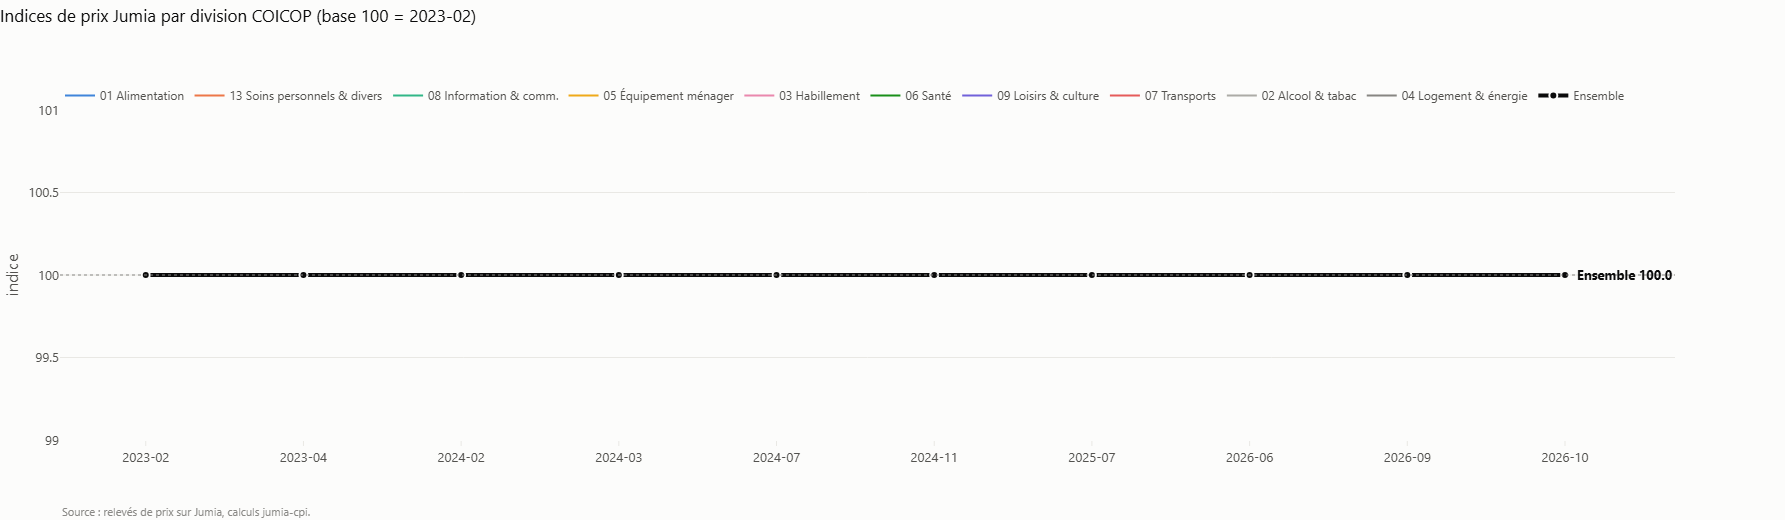

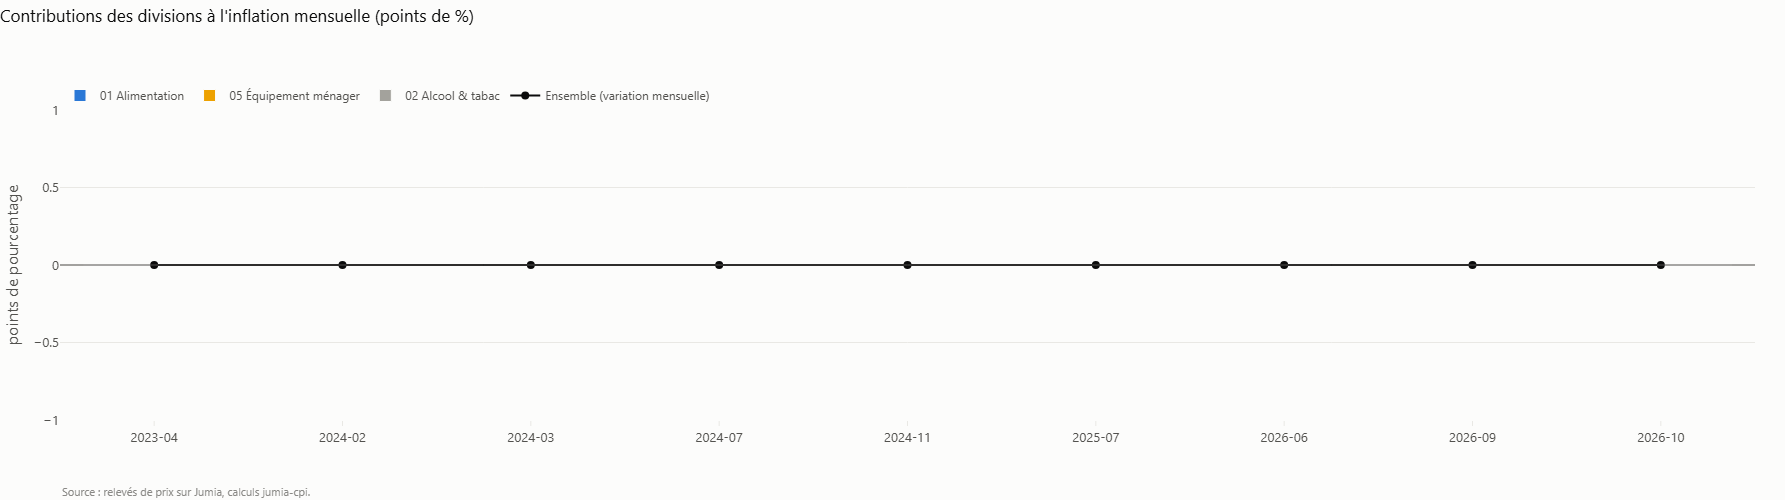

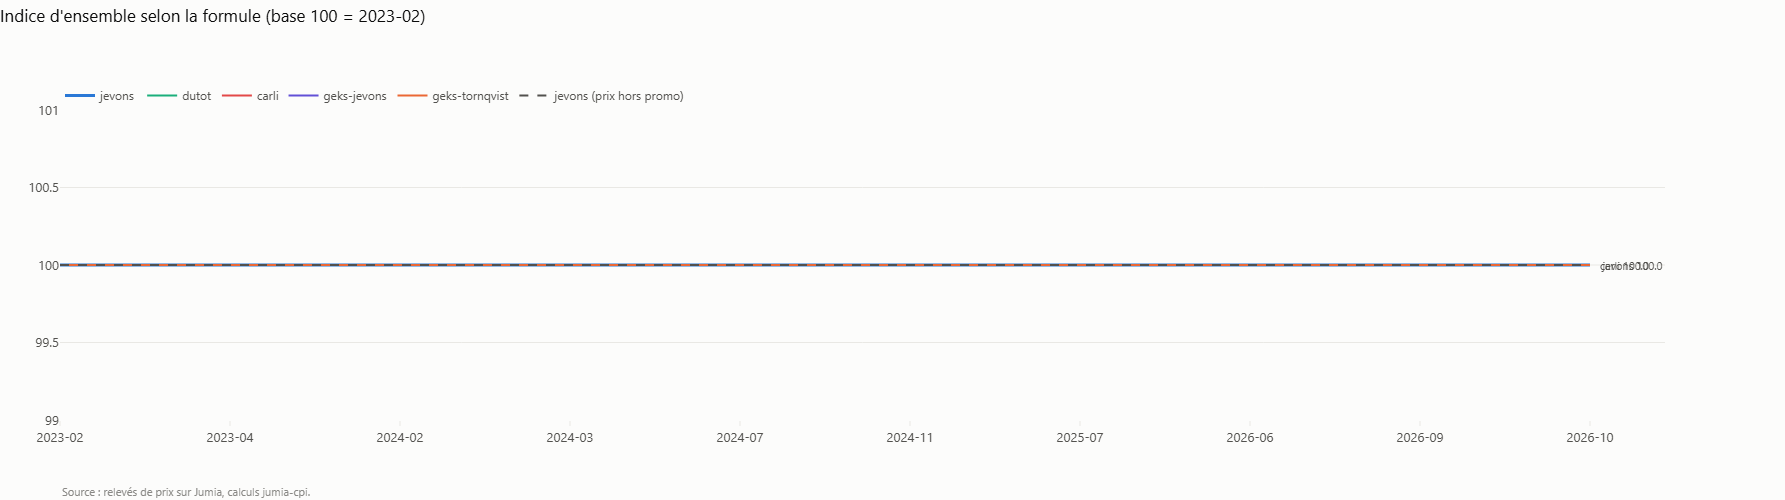

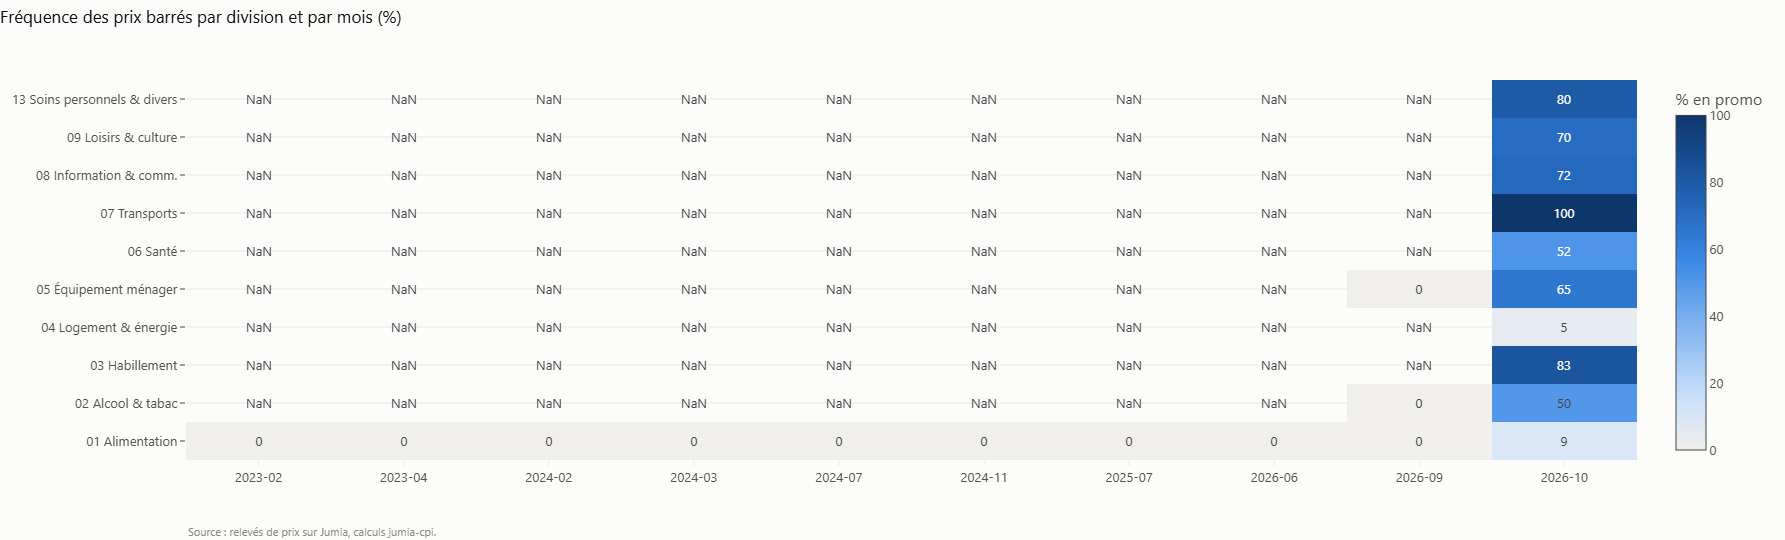

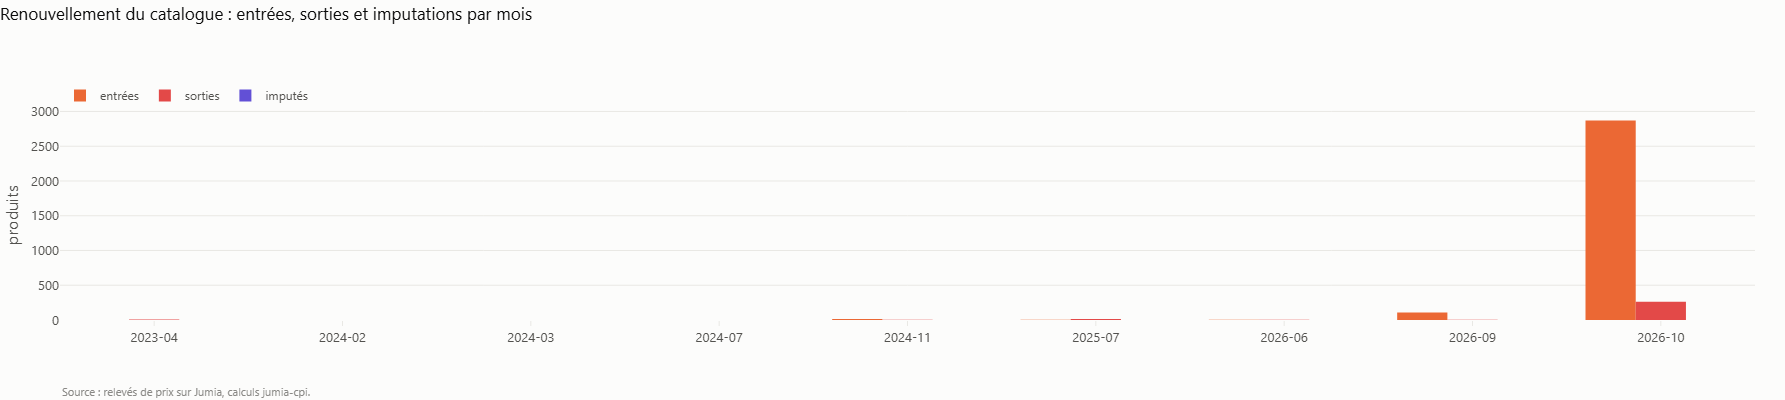

In [9]:
#@title Graphiques { display-mode: "form" }
FIGURES = []
for nom, args in (("fig_indices", (RES["indices"], RES["reference"])),
                  ("fig_contributions", (RES["contributions"], ENS)),
                  ("fig_methods", (RES["method_comparison"], RES["reference"])),
                  ("fig_promo", (RES["promo"],)),
                  ("fig_diagnostics", (RES["diagnostics"],))):
    fabrique = getattr(viz, nom, None)
    if fabrique is None:
        continue
    try:
        figure = fabrique(*args)
        FIGURES.append((nom, figure))
        figure.show()
    except Exception as erreur:
        print("graphique {} non produit ({})".format(nom, type(erreur).__name__))

## 8 · Comparaison avec l'IPC officiel — facultatif

Déposez la série officielle en CSV, deux colonnes : `period` (`2026-01`) et
`cpi`. Indiquez son chemin dans `CSV_OFFICIEL`, cellule 1.

In [10]:
#@title Comparer à l'IPC officiel { display-mode: "form" }
COMP, STATS = None, {}
chemin_off = CSV_OFFICIEL.strip() or (
    str(RACINE / "data" / "exemple" / "ipc_officiel_exemple.csv")
    if SOURCE == "exemple" else "")
if chemin_off and Path(chemin_off).exists():
    try:
        OFF = official.load_official_csv(chemin_off)
        COMP, STATS = official.compare(ENS[["period", "index"]], OFF)
        for phrase in messages.interpret_comparison(STATS, Path(chemin_off).name):
            encadre(phrase)
        for nom in ("fig_comparison", "fig_comparison_monthly"):
            fabrique = getattr(viz, nom, None)
            if fabrique is None:
                continue
            try:
                fabrique(COMP, Path(chemin_off).name).show()
            except Exception:
                pass
        display(viz.table(COMP.tail(12), caption="En ligne contre IPC officiel"))
    except Exception as erreur:
        encadre("Le fichier n'a pas pu être lu : {}. Il lui faut deux colonnes "
                "— « period » au format 2026-01, et « cpi » avec des nombres, "
                "sans case vide.".format(erreur), *ATTENTION)
else:
    encadre("Aucun IPC officiel fourni : la comparaison est sautée. Elle est "
            "facultative.")

## 9 · Le rapport

Un fichier HTML autonome : graphiques compris, aucun lien externe. Il s'ouvre
dans n'importe quel navigateur et se transmet par courriel.

In [11]:
#@title Produire et télécharger le rapport { display-mode: "form" }
dossier = Path(S.out_dir)
dossier.mkdir(parents=True, exist_ok=True)
chemin = dossier / "rapport.html"
sous_titre = panel.origine_fusionnee(MANIFESTES, SOURCES_PANEL)

sections = [
    ("Origine des données", [sous_titre, OBS.head(12)]),
    ("Indices", [dict(FIGURES).get("fig_indices"),
                 RES["indices"].pivot(index="period", columns="série",
                                      values="index").reset_index()]),
    ("Comparaison des formules", [dict(FIGURES).get("fig_methods"),
                                  RES["method_comparison"].tail(12)]),
    ("Pondérations appliquées", [pd.DataFrame(
        {"division": list(POIDS), "poids": list(POIDS.values())})]),
    ("Diagnostics", [dict(FIGURES).get("fig_diagnostics"),
                     RES["diagnostics"].tail(12)]),
]
if COMPARAISON is not None and len(COMPARAISON["tableau"]):
    sections.insert(1, ("Méthodes de classification comparées",
                        [COMPARAISON["tableau"]]))
if COMP is not None and len(COMP):
    sections.append(("Comparaison avec l'IPC officiel", [COMP.tail(12)]))

try:
    export.build_report(chemin, TITRE, sous_titre, sections)
    encadre("Rapport écrit : <code>{}</code> ({:.0f} Ko)".format(
        chemin, chemin.stat().st_size / 1024), *SUCCES)
    if SUR_COLAB:
        from google.colab import files
        files.download(str(chemin))
except Exception as erreur:
    encadre("Le rapport n'a pas pu être produit : {}. Les tableaux ci-dessus "
            "restent valables.".format(erreur), *ATTENTION)

---

## Ce que cet indice mesure, et ce qu'il ne mesure pas

Il mesure l'évolution des **prix affichés en ligne**, à qualité constante —
c'est-à-dire sur les mêmes références d'un mois sur l'autre. C'est un
**indicateur complémentaire**, pas un substitut à l'IPC officiel.

| Limite | Pourquoi elle compte |
|---|---|
| Les acheteurs en ligne sont urbains et connectés | les marchés de plein air et l'informel ne sont pas couverts |
| Seuls des biens | logement, transports, santé, éducation absents |
| Prix affichés, pas prix payés | pas de quantités vendues ; les promotions pèsent |
| Le catalogue se renouvelle vite | les nouveautés n'entrent qu'au mois suivant |
| La classification est imparfaite | la cellule 5 dit de combien, **sur vos données** |

**Avant de diffuser un chiffre**, vérifiez quatre choses : que les pondérations
sont celles de votre institut et non des parts égales ; que le fichier porte un
manifeste, sinon la provenance ne peut pas être citée ; qu'il ne s'agit pas du
jeu de démonstration ; et que le banc d'essai a tourné sur **vos** données.

### Si quelque chose ne marche pas

| Message | Ce qu'il faut faire |
|---|---|
| « Ce fichier ne peut pas être utilisé » | la raison est écrite juste en dessous, en français |
| « Un seul mois de relevés » | normal au premier passage : il faut une seconde collecte |
| « Aucun modèle joignable » | sans conséquence, les règles prennent le relais |
| « Jeu de référence inutilisable » | produisez l'échantillon à annoter, cellule 5 bis |
| Une cellule reste grise longtemps | l'installation ou la classification travaillent ; attendez |

Pour toute question sur la collecte elle-même, c'est le notebook 1 qu'il faut
regarder — il tourne sur le poste de l'institut.

<div style='font-family:Segoe UI,Roboto,Helvetica,Arial,sans-serif;margin-top:8px;padding:14px 18px;border-top:4px solid #00703C;background:#F3F6F4;border-radius:0 0 10px 10px;font-size:13px;color:#33433A'><div>Fin du parcours. Les archives se renouvellent chaque mois : relancez les notebooks 1 et 2, puis celui-ci.</div><div style='margin-top:6px;color:#5B6B62'><b style='color:#0B3D2E'>DI4A · Banque africaine de développement</b> — Atelier « Big Data pour les statistiques macroéconomiques », Maurice, 26 – 30 octobre 2026 · Notebook 3 / 3</div></div>